# Notebook 01: Derivatives Lab — Sensitivity, Secants & The IEEE-754 Truncation–Roundoff V-Curve

In this notebook we explore:
1. **Physical Sensitivity & Secant-to-Tangent Convergence:** Visualizing how the finite-difference secant slope approaches the exact analytical derivative $f'(x_0)$ computed by `ScalarValue`.
2. **Forward Difference $\mathcal{O}(h)$ vs. Centered Difference $\mathcal{O}(h^2)$:** Sweeping step size $h \in [10^{-16}, 10^0]$ across 16 orders of magnitude.
3. **Catastrophic Floating-Point Cancellation:** Observing why choosing $h < 10^{-10}$ causes relative error to explode as $\mathcal{O}(\epsilon_{\text{mach}} / h)$, and verifying the theoretical optimal step sizes $h_{\text{fwd}}^* \approx \epsilon_{\text{mach}}^{1/2} \approx 1.5 \times 10^{-8}$ and $h_{\text{cen}}^* \approx \epsilon_{\text{mach}}^{1/3} \approx 6 \times 10^{-6}$.

In [1]:
import sys
from pathlib import Path
from typing import Union

import matplotlib.pyplot as plt
import numpy as np

repo_root = Path.cwd()
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from src.autograd_engine import ScalarValue
from src.plot_theme import (
    AMBER,
    CORAL,
    CYAN,
    EMERALD,
    PURPLE,
    SLATE_BLUE,
    TEXT_MUTED,
    apply_github_dark_style,
    save_fig,
)

apply_github_dark_style()

## 1. Analytical Autograd Derivative vs. Forward & Centered Finite Differences

Consider the composite non-linear function:
$$f(x) = \exp(0.6 x) \cdot \tanh(1.4 x) + 0.5 x^3$$
evaluated at $x_0 = 1.15$. We compute the exact analytical derivative $f'(x_0)$ using `ScalarValue.backward()` and sweep 200 log-spaced step sizes $h \in [10^{-16}, 10^0]$.

In [2]:
def f_num(x: Union[float, np.ndarray]) -> Union[float, np.ndarray]:
    return np.exp(0.6 * x) * np.tanh(1.4 * x) + 0.5 * (x ** 3)


def f_autograd(x_val: float):
    x = ScalarValue(x_val, label="x")
    y = (x * 0.6).exp() * (x * 1.4).tanh() + (x ** 3) * 0.5
    return y, x


x0 = 1.15
y_node, x_node = f_autograd(x0)
y_node.backward()
exact_grad = x_node.grad
f_x0 = y_node.data

h_values = np.logspace(-16, 0, 200)

# Forward finite differences: D_fwd(h) = (f(x0 + h) - f(x0)) / h
fwd_diffs = (f_num(x0 + h_values) - f_x0) / h_values
err_fwd = np.abs(fwd_diffs - exact_grad) / np.abs(exact_grad)

# Centered finite differences: D_cen(h) = (f(x0 + h) - f(x0 - h)) / (2h)
cen_diffs = (f_num(x0 + h_values) - f_num(x0 - h_values)) / (2.0 * h_values)
err_cen = np.abs(cen_diffs - exact_grad) / np.abs(exact_grad)

eps_mach = np.finfo(np.float64).eps
h_opt_fwd = np.sqrt(eps_mach)
h_opt_cen = eps_mach ** (1.0 / 3.0)

print(f"Evaluation Point x0 = {x0:.2f} | f(x0) = {f_x0:.6f}")
print(f"Exact Autograd Derivative f'(x0) = {exact_grad:.10f}")
print(f"Machine Epsilon eps_mach = {eps_mach:.3e}")
print(f"Theoretical Optimal h (Forward):  h* = sqrt(eps)   ~= {h_opt_fwd:.3e} | Min Err = {np.nanmin(err_fwd):.3e}")
print(f"Theoretical Optimal h (Centered): h* = eps^(1/3)   ~= {h_opt_cen:.3e} | Min Err = {np.nanmin(err_cen):.3e}")

Evaluation Point x0 = 1.15 | f(x0) = 2.600956
Exact Autograd Derivative f'(x0) = 3.5005324973
Machine Epsilon eps_mach = 2.220e-16
Theoretical Optimal h (Forward):  h* = sqrt(eps)   ~= 1.490e-08 | Min Err = 9.059e-10
Theoretical Optimal h (Centered): h* = eps^(1/3)   ~= 6.055e-06 | Min Err = 2.433e-12


## 2. Two-Panel Diagnostic Dashboard (`01_numerical_gradient_epsilon_tradeoff.png`)

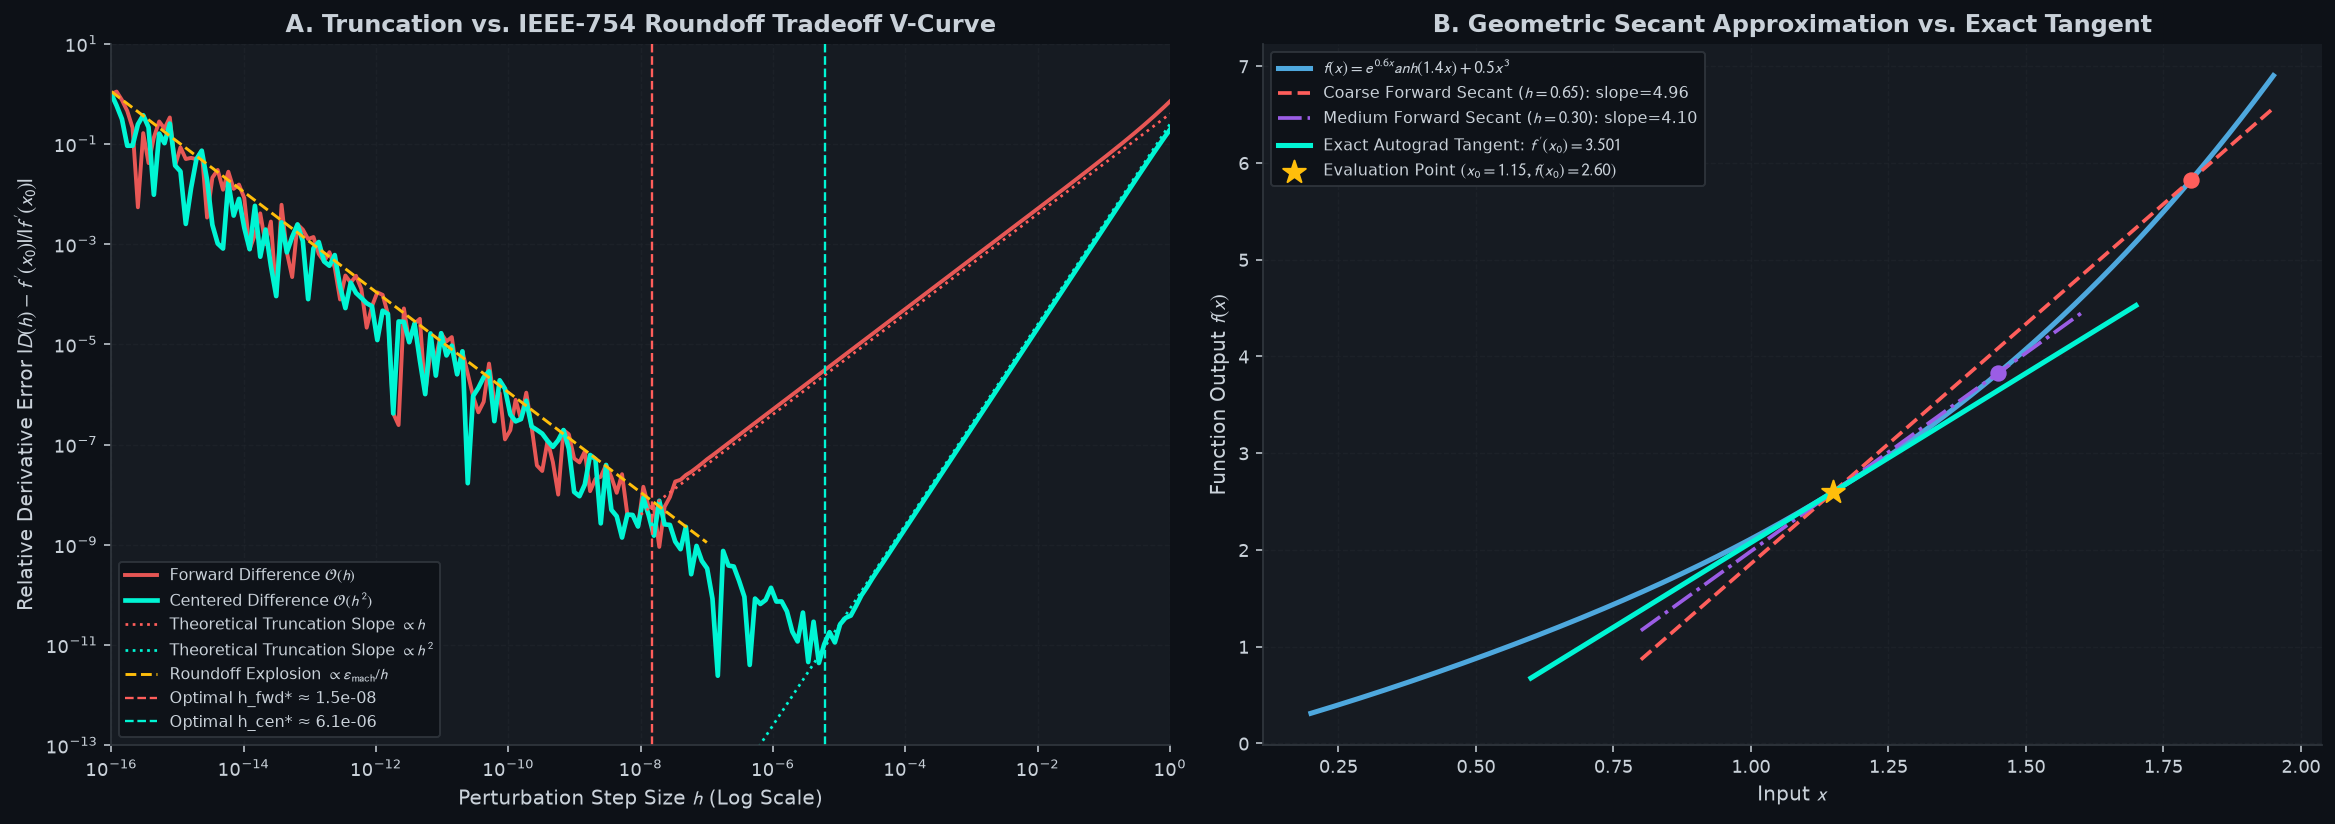

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16.8, 6.0))

# Panel A: The Truncation-Roundoff V-Curve
ax1.loglog(h_values, err_fwd, color=CORAL, linewidth=2.0, alpha=0.9, label=r"Forward Difference $\mathcal{O}(h)$")
ax1.loglog(h_values, err_cen, color=CYAN, linewidth=2.4, label=r"Centered Difference $\mathcal{O}(h^2)$")

# Theoretical asymptotic error guide lines
h_trunc = np.logspace(-8, 0, 50)
ax1.loglog(h_trunc, 0.4 * h_trunc, color=CORAL, linestyle=":", linewidth=1.4, label=r"Theoretical Truncation Slope $\propto h$")
ax1.loglog(h_trunc, 0.25 * (h_trunc ** 2), color=CYAN, linestyle=":", linewidth=1.4, label=r"Theoretical Truncation Slope $\propto h^2$")

h_round = np.logspace(-16, -7, 50)
ax1.loglog(h_round, 0.5 * (eps_mach / h_round), color=AMBER, linestyle="--", linewidth=1.5, label=r"Roundoff Explosion $\propto \epsilon_{\mathrm{mach}} / h$")

# Mark theoretical optimal step sizes
ax1.axvline(h_opt_fwd, color=CORAL, linestyle="--", linewidth=1.2, label=f"Optimal h_fwd* ≈ {h_opt_fwd:.1e}")
ax1.axvline(h_opt_cen, color=CYAN, linestyle="--", linewidth=1.2, label=f"Optimal h_cen* ≈ {h_opt_cen:.1e}")

ax1.set_xlim(1e-16, 1.0)
ax1.set_ylim(1e-13, 10.0)
ax1.set_xlabel("Perturbation Step Size $h$ (Log Scale)")
ax1.set_ylabel("Relative Derivative Error $|D(h) - f'(x_0)| / |f'(x_0)|$")
ax1.set_title("A. Truncation vs. IEEE-754 Roundoff Tradeoff V-Curve")
ax1.legend(loc="lower left", fontsize=8.1)

# Panel B: Geometric Secant-to-Tangent Sensitivity Visualization
x_plot = np.linspace(0.2, 1.95, 300)
y_plot = f_num(x_plot)
ax2.plot(x_plot, y_plot, color=SLATE_BLUE, linewidth=2.6, label=r"$f(x) = e^{0.6x}	anh(1.4x) + 0.5x^3$")

for h_sec, col_s, ls_s, lbl_s in [
    (0.65, CORAL, "--", "Coarse Forward Secant ($h=0.65$)"),
    (0.30, PURPLE, "-.", "Medium Forward Secant ($h=0.30$)"),
]:
    slope_s = (f_num(x0 + h_sec) - f_x0) / h_sec
    x_seg = np.linspace(x0 - 0.35, x0 + h_sec + 0.15, 50)
    ax2.plot(x_seg, f_x0 + slope_s * (x_seg - x0), color=col_s, linestyle=ls_s, linewidth=1.9, label=f"{lbl_s}: slope={slope_s:.2f}")
    ax2.scatter([x0 + h_sec], [f_num(x0 + h_sec)], color=col_s, s=55, zorder=5)

# Exact analytical tangent line from Reverse-Mode Autograd
x_tan = np.linspace(x0 - 0.55, x0 + 0.55, 80)
ax2.plot(x_tan, f_x0 + exact_grad * (x_tan - x0), color=CYAN, linewidth=2.6, label=f"Exact Autograd Tangent: $f'(x_0)={exact_grad:.3f}$")
ax2.scatter([x0], [f_x0], color=AMBER, s=150, marker="*", zorder=8, label=f"Evaluation Point $(x_0={x0}, f(x_0)={f_x0:.2f})$")
ax2.set_xlabel("Input $x$")
ax2.set_ylabel("Function Output $f(x)$")
ax2.set_title("B. Geometric Secant Approximation vs. Exact Tangent")
ax2.legend(loc="upper left", fontsize=8.4)

fig.tight_layout()
assets_dir = Path("assets")
assets_dir.mkdir(parents=True, exist_ok=True)
save_fig(fig, assets_dir / "01_numerical_gradient_epsilon_tradeoff.png")
plt.show()